# OCR resource lab — a curiosity side quest

**Historical side experiment.** Phase-status statements describe this lab's
handoff, not subsequent closeout. Current status and adopted settings are in
the [Phase 3 delivery record](../docs/phases/phase-3.md). Lab variants remain
separate from the official pipeline; original code and outputs are unchanged.

What actually costs time and memory when seven cropped fields travel through
TrOCR? Can a smaller “pod” be fast if its thread policy matches its budget?

This notebook analyses a completed, bounded experiment and can launch a fresh
one. It is **not Workshop 10**, does not close Phase 3, and changes no official
pipeline/model settings. The test split stays sealed. The full executable
[worker](../experiments/ocr_resource_profile.py) is deliberately separate from
the analysis, so CPU/RAM constraints apply to the worker, not this kernel.

Read the [short report](../docs/experiments/ocr-resource-profile.md) first, then the
[concept notes](../docs/learning/ocr-resource-profiling.md) when a measurement
needs explanation.

In [1]:
from pathlib import Path
import os
import sys
import tempfile
import json

os.environ.setdefault("MPLCONFIGDIR", tempfile.mkdtemp(prefix="kyc-ocr-profile-mpl-"))
root = Path.cwd().resolve()
if not (root / "PROJECT.md").exists():
    root = root.parent
assert (root / "PROJECT.md").exists()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from IPython.display import Image, Markdown, display
import pandas as pd
from experiments.ocr_resource_profile import run_experiment, run_thread_control
from experiments.ocr_resource_analysis import load_run, dashboard, load_figure, trace_figure, tables

policy = json.loads((root / "configs/ocr_resource_profile_v1.json").read_text())
display(pd.Series(policy, dtype=object))

/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


purpose                          curiosity side experiment; not the official be...
seed                                                                          2026
cpu_profiles                                    {'roomy': '400%', 'small': '100%'}
memory_max                                                                      4G
memory_swap_max                                                                  0
pytorch_gpu_allocator_cap_gib                                                  1.0
torch_threads                                                                    4
repetitions                                                                      2
transfer_repetitions                                                            60
queue_pending_capacity                                                           4
load_duration_seconds                                                            5
quiet_arrivals_per_second                                                      1.5
surg

## 1. Real limits, small scope

The worker uses an ephemeral systemd **user** service with CPU quotas of 400% or
100%, MemoryMax=4G, MemorySwapMax=0, and a ten-minute safety timeout. These are
real cgroup limits. A 1 GiB PyTorch allocator cap is also checked, but it does
not limit GPU compute or CUDA context memory. Nothing is installed or deployed.

Both initial profiles use four CPU threads. A separate, recorded follow-up
changes thread pools to one under the same 100% CPU quota. See the amendment
before interpreting the third profile as a prespecified original case.

By default we read the recorded run. Set `RUN_FRESH_EXPERIMENT = True` only when
you want to launch the workers again with GPU and user-systemd access. This takes
a few minutes and writes fresh local output directories.

In [2]:
RUN_FRESH_EXPERIMENT = False
recorded_run_id = "20261012T235119768783Z"
if RUN_FRESH_EXPERIMENT:
    run_directory = run_experiment()
    run_thread_control(run_directory)
else:
    run_directory = root / "outputs" / "ocr_resource_profile" / recorded_run_id
assert run_directory.is_dir(), "Local raw artifacts are Git-ignored; rerun the lab on a fresh clone."
data = load_run(run_directory)
assert len(data["metadata"]) == 3
print("Run:", run_directory.name)
print("Timed documents:", len(data["requests"]))
display(data["latency"].round(3))

Run: 20261012T235119768783Z
Timed documents: 540


,profile,variant,requests,median_ms,p95_ms,cpu_ms,prediction_agreement
0,roomy,batch7_kv,60,197.933,207.615,248.193,1.0
1,roomy,kv,60,280.403,296.036,559.515,1.0
2,roomy,reference,60,288.652,312.271,570.360,1.0
3,small,batch7_kv,60,199.913,215.594,201.292,1.0
4,small,kv,60,797.525,1395.368,893.708,1.0
5,small,reference,60,805.376,1283.160,828.179,1.0
6,small_tuned,batch7_kv,60,197.322,200.286,197.647,1.0
7,small_tuned,kv,60,281.353,296.661,283.076,1.0
8,small_tuned,reference,60,297.253,319.628,299.001,1.0


## 2. Inside a completed request

The request begins at canonical RGB already in RAM. The source loader and crop,
normalization, validation, and scoring definitions come from `04d` cells 1 and
3–24, with explicit source hashes. No fitting cells are executed. Only the
30 validation observations are selected; references are scored outside timing.

Each stage waits for completion. `generation_ms` includes encoder, decoder,
CPU dispatch, GPU work, and synchronization—not just GPU busy time. Process CPU
time includes all threads and can exceed wall time. The three variants are
sequential/no KV, sequential/KV, and one seven-field batch/KV. Greedy decoding,
float32, weights, processor, and maximum length remain fixed.

Prediction checks are mandatory: batching or caching is not a free optimization
if it changes the recognized strings.

,crop_ms,processor_ms,h2d_ms,generation_ms,decode_ms,postprocess_ms,other_ms,total_ms
variant,,,,,,,,
batch7_kv,0.070,3.868,1.212,193.060,0.080,0.099,0.056,198.446
kv,0.060,5.709,1.695,273.835,0.381,0.099,0.072,281.852
reference,0.061,5.852,1.685,284.100,0.390,0.098,0.072,292.258


,processor_load_ms,model_load_cpu_ms,weights_to_gpu_ms
roomy,218.40,115.85,177.24
small,218.19,136.20,182.81
small_tuned,217.01,162.44,168.97


First process-local request, roomy: 910.1 ms


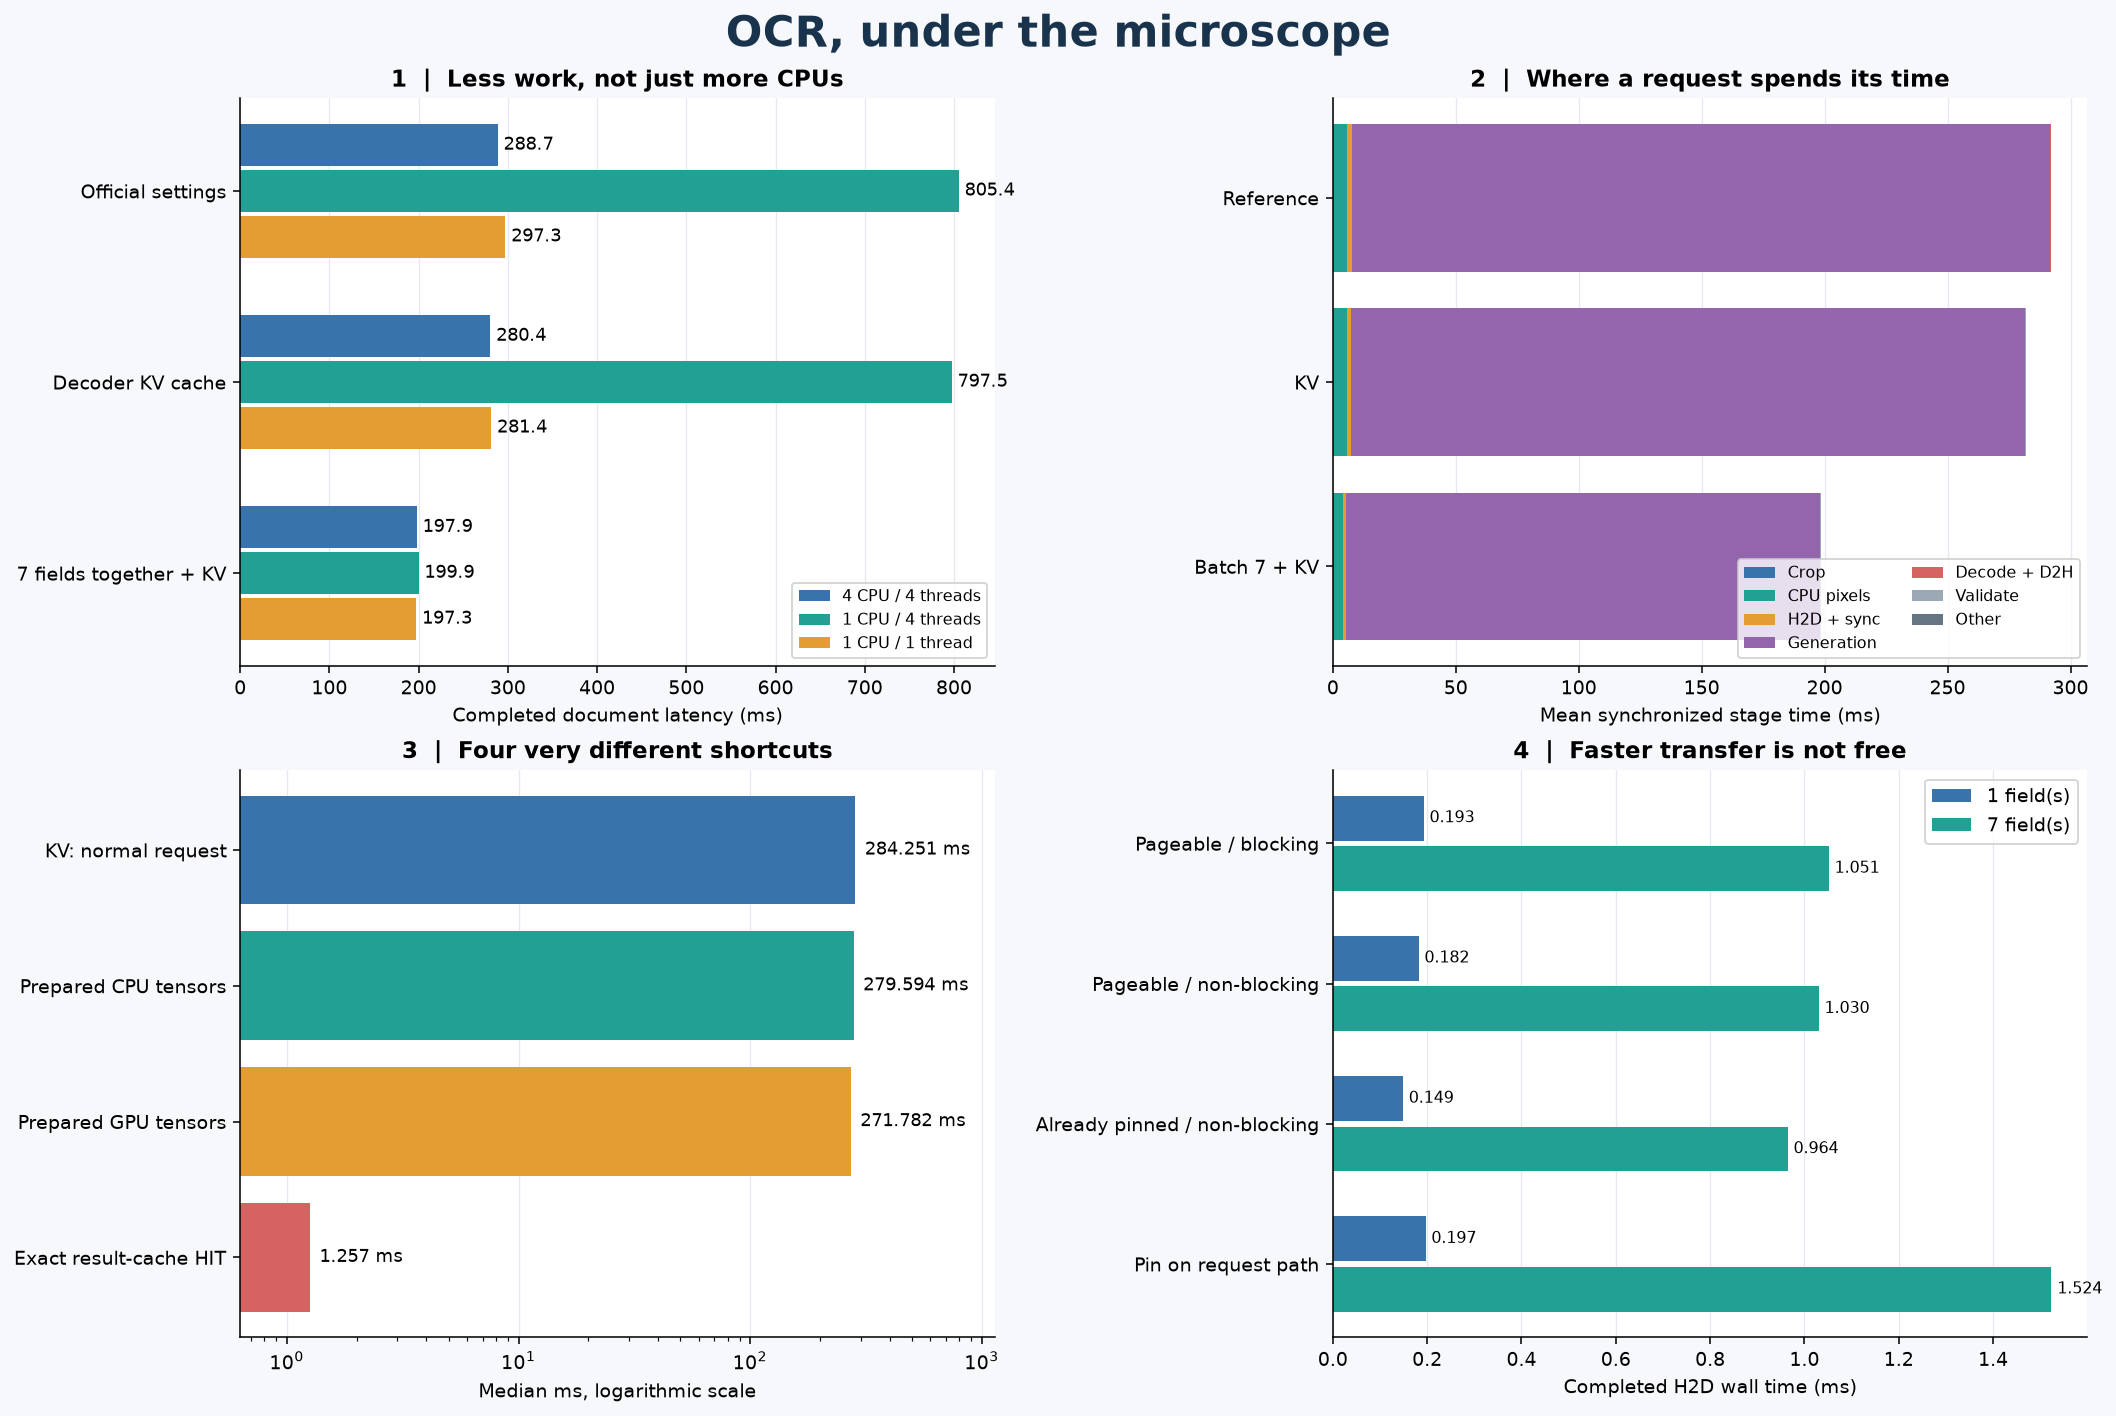

In [3]:
assert data["requests"].exact_prediction_replay.all()
stages = ["crop_ms", "processor_ms", "h2d_ms", "generation_ms", "decode_ms", "postprocess_ms", "other_ms", "total_ms"]
display(data["requests"].query("profile == 'roomy'").groupby("variant")[stages].mean().round(3))
display(pd.DataFrame({
    profile: {key: value for key, value in meta["startup"].items() if key != "first_request"}
    for profile, meta in data["metadata"].items()
}).T.round(2))
print("First process-local request, roomy:", round(data["metadata"]["roomy"]["startup"]["first_request"]["total_ms"], 2), "ms")
figure_directory = run_directory / "figures"
figure_directory.mkdir(exist_ok=True)
dashboard(data, figure_directory / "dashboard.png")
display(Image(filename=str(figure_directory / "dashboard.png")))

## 3. Data movement and different cache contracts

One field tensor occupies 1.6875 MiB; seven occupy 11.8125 MiB. Transfer tests
use preallocated CUDA destination buffers, discard five warm-ups, then record
60 completed copies per case. Seven fields here are one packed tensor. The
normal request's H2D stage additionally includes allocation and seven separate
copy/synchronization boundaries when running sequentially.

Already-pinned memory and pinning on the request path are separate cases.
`non_blocking=True` is not an overlap demonstration: this single-stream test
waits for completion. The event span excludes CPU pinning; completed wall time
includes it. Compare both columns.

Prepared-input caches use three known repeated observations; fill cost is
excluded and crop handling remains. The eight-slot result LRU instead hashes
actual pixels plus geometry and pipeline version, and restores a stored response.
It has three misses and 60 intentional hits. That does not predict traffic's hit
rate. A new photo or pipeline version must miss.

In [4]:
transfer_table, memory_table = tables(data)
display(transfer_table.round(4))
display(data["prepared"].groupby("variant").total_ms.agg(["count", "median"]).round(3))
display(data["result_cache"].groupby("kind").total_ms.agg(["count", "median"]).round(3))
display(pd.Series(data["metadata"]["roomy"]["cache_storage_bytes"], name="Cache bytes"))

,fields,mode,completed_wall_ms,cuda_stream_ms
0,1,pageable_blocking,0.1926,0.1840
1,1,pageable_nonblocking,0.1818,0.1724
2,1,pin_inside_request,0.1965,0.1452
3,1,pre_pinned_nonblocking,0.1486,0.1399
4,7,pageable_blocking,1.0515,1.0428
5,7,pageable_nonblocking,1.0302,1.0209
6,7,pin_inside_request,1.5238,0.9778
7,7,pre_pinned_nonblocking,0.9645,0.9549


,count,median
variant,,
kv,15,284.251
prepared_cpu,15,279.594
prepared_gpu,15,271.782


,count,median
kind,,
hit,60,1.257
miss,3,277.592


cpu        37158912
gpu        37158912
results        2652
Name: Cache bytes, dtype: int64

## 4. A real queue, not a throughput formula

A producer schedules arrivals independently of completion. One GPU worker
serves them; four pending slots are allowed, plus the active request. Full queues
reject immediately. The worker runs 1.5/s and 8/s cases, a batched 8/s case, and
a 12-request simultaneous burst. Each paced case offers arrivals for five
seconds, then drains admitted work. The producer shares the worker's CPU budget;
actual arrival lateness is retained.

`response = queue wait + service`. Response p95 applies only to completed
requests; always read rejection counts alongside it. The first two Gantt panels
use identical time scales. Lower panels show sampled process CPU/RSS and
PyTorch live GPU allocation, not whole-machine utilization.

,profile,case,offered,completed,rejected,service_median_ms,response_p50_ms,response_p95_ms,queue_p95_ms,max_arrival_lateness_ms
0,roomy,quiet,8,8,0,299.005,299.152,303.230,0.161,0.109
1,roomy,surge,40,21,19,289.702,1363.366,1449.718,1153.245,0.311
2,roomy,surge_batch7,40,29,11,196.301,880.905,969.890,772.787,0.189
3,roomy,burst12,12,4,8,291.989,727.656,1123.872,830.149,0.030
4,small,quiet,8,8,0,936.870,1663.890,2486.510,1659.624,23.547
5,small,surge,40,9,31,994.733,4011.243,4520.442,3613.704,70.768
6,small,surge_batch7,40,29,11,199.845,920.876,997.865,798.105,0.098
7,small,burst12,12,4,8,707.993,1738.320,2915.173,1980.657,0.028
8,small_tuned,quiet,8,8,0,298.230,298.348,303.069,0.164,0.093
9,small_tuned,surge,40,21,19,291.707,1373.437,1466.734,1174.969,2.498


,profile,peak_sampled_rss_mib,peak_sampled_torch_gpu_mib,cgroup_peak_mib,throttle_seconds
0,roomy,2033.96,322.53,1399.65,0.09
1,small,1851.24,322.53,1341.68,211.49
2,small_tuned,1846.39,322.53,1198.71,0.14


roomy cpu.max: 400000 100000 memory.max: 4294967296 memory.events: low 0; high 0; max 0; oom 0; oom_kill 0; oom_group_kill 0; sock_throttled 0
small cpu.max: 100000 100000 memory.max: 4294967296 memory.events: low 0; high 0; max 0; oom 0; oom_kill 0; oom_group_kill 0; sock_throttled 0
small_tuned cpu.max: 100000 100000 memory.max: 4294967296 memory.events: low 0; high 0; max 0; oom 0; oom_kill 0; oom_group_kill 0; sock_throttled 0


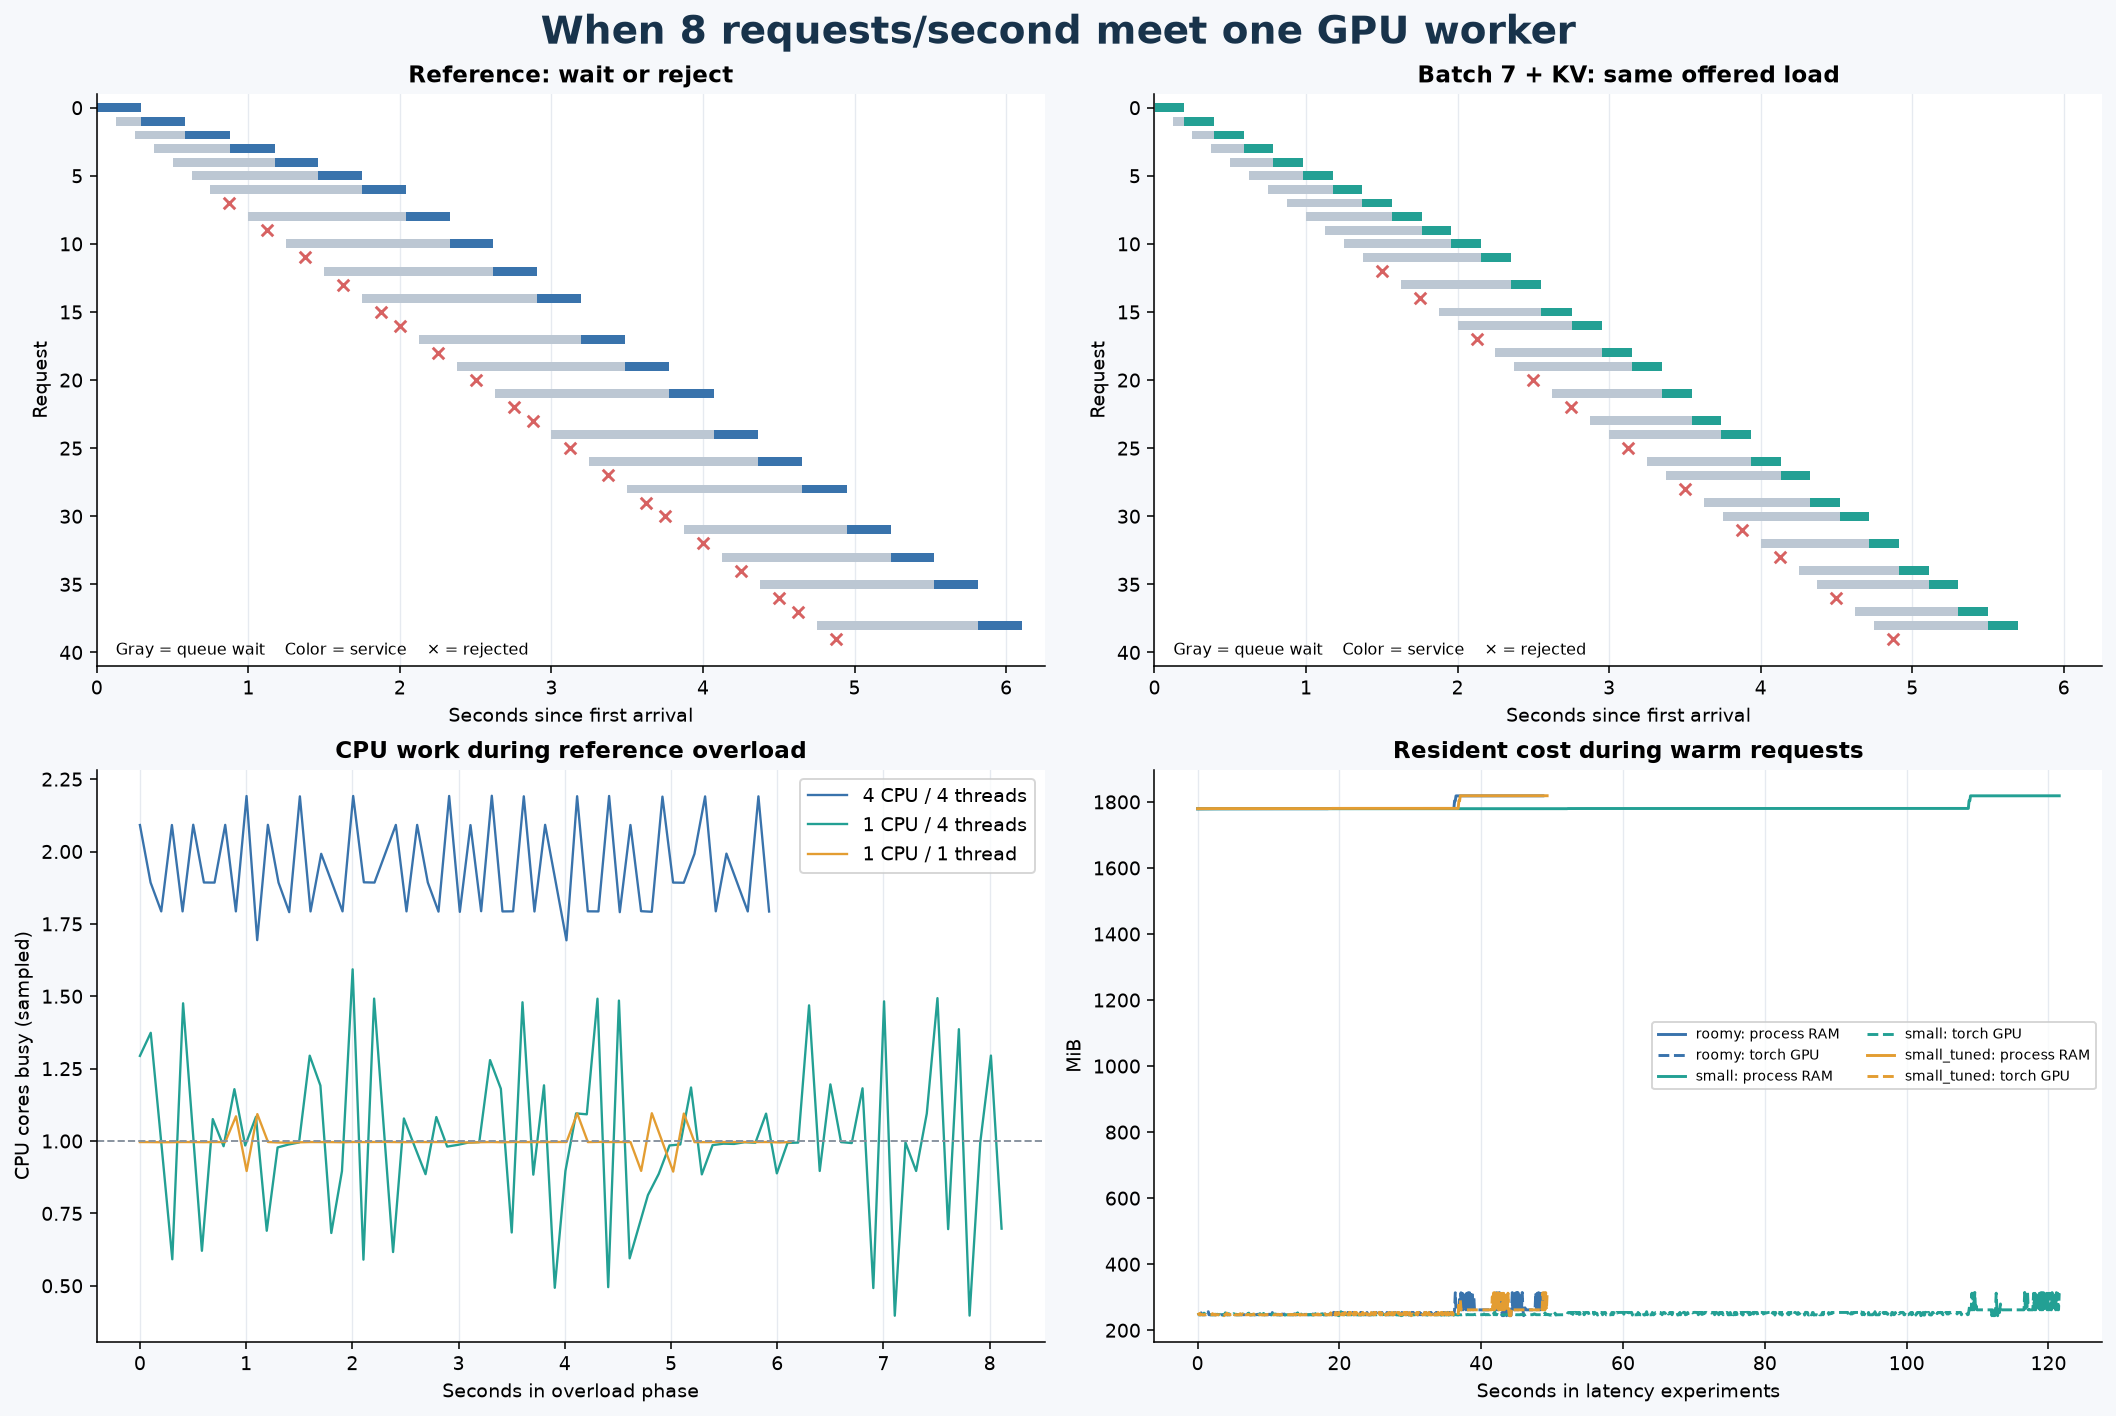

In [5]:
display(data["queue_summary"].round(3))
display(memory_table.round(2))
for profile, meta in data["metadata"].items():
    print(profile, "cpu.max:", meta["initial_cgroup"]["cpu_max"],
          "memory.max:", meta["initial_cgroup"]["memory_max"],
          "memory.events:", meta["final_cgroup"]["memory_events"].replace("\n", "; "))
load_figure(data, figure_directory / "load.png")
display(Image(filename=str(figure_directory / "load.png")))

## 5. Look at the GPU's actual timeline

Two short PyTorch CPU/CUDA traces cover one nationality crop, with and without
KV caching. They are **instrumented diagnostics**, excluded from all latency
statistics above. Yellow CPU scope = image processor; teal = H2D; blue =
generation. The GPU rows show actual kernels/copies, including small internal
generation transfers—not only the large input tensor.

We compute GPU kernel union time from CUDA trace intervals rather than adding
CPU-attributed and standalone-kernel rows, which can double-count work. A trace's
CPU generation scope includes waits and instrumentation overhead; gaps here
must not be presented as a production GPU-utilization measurement.

,variant,traced_request_ms,gpu_kernel_union_ms,gpu_kernel_count,gpu_copy_count
0,reference,95.927,47.796,2180,81
1,kv,66.837,33.771,2096,81


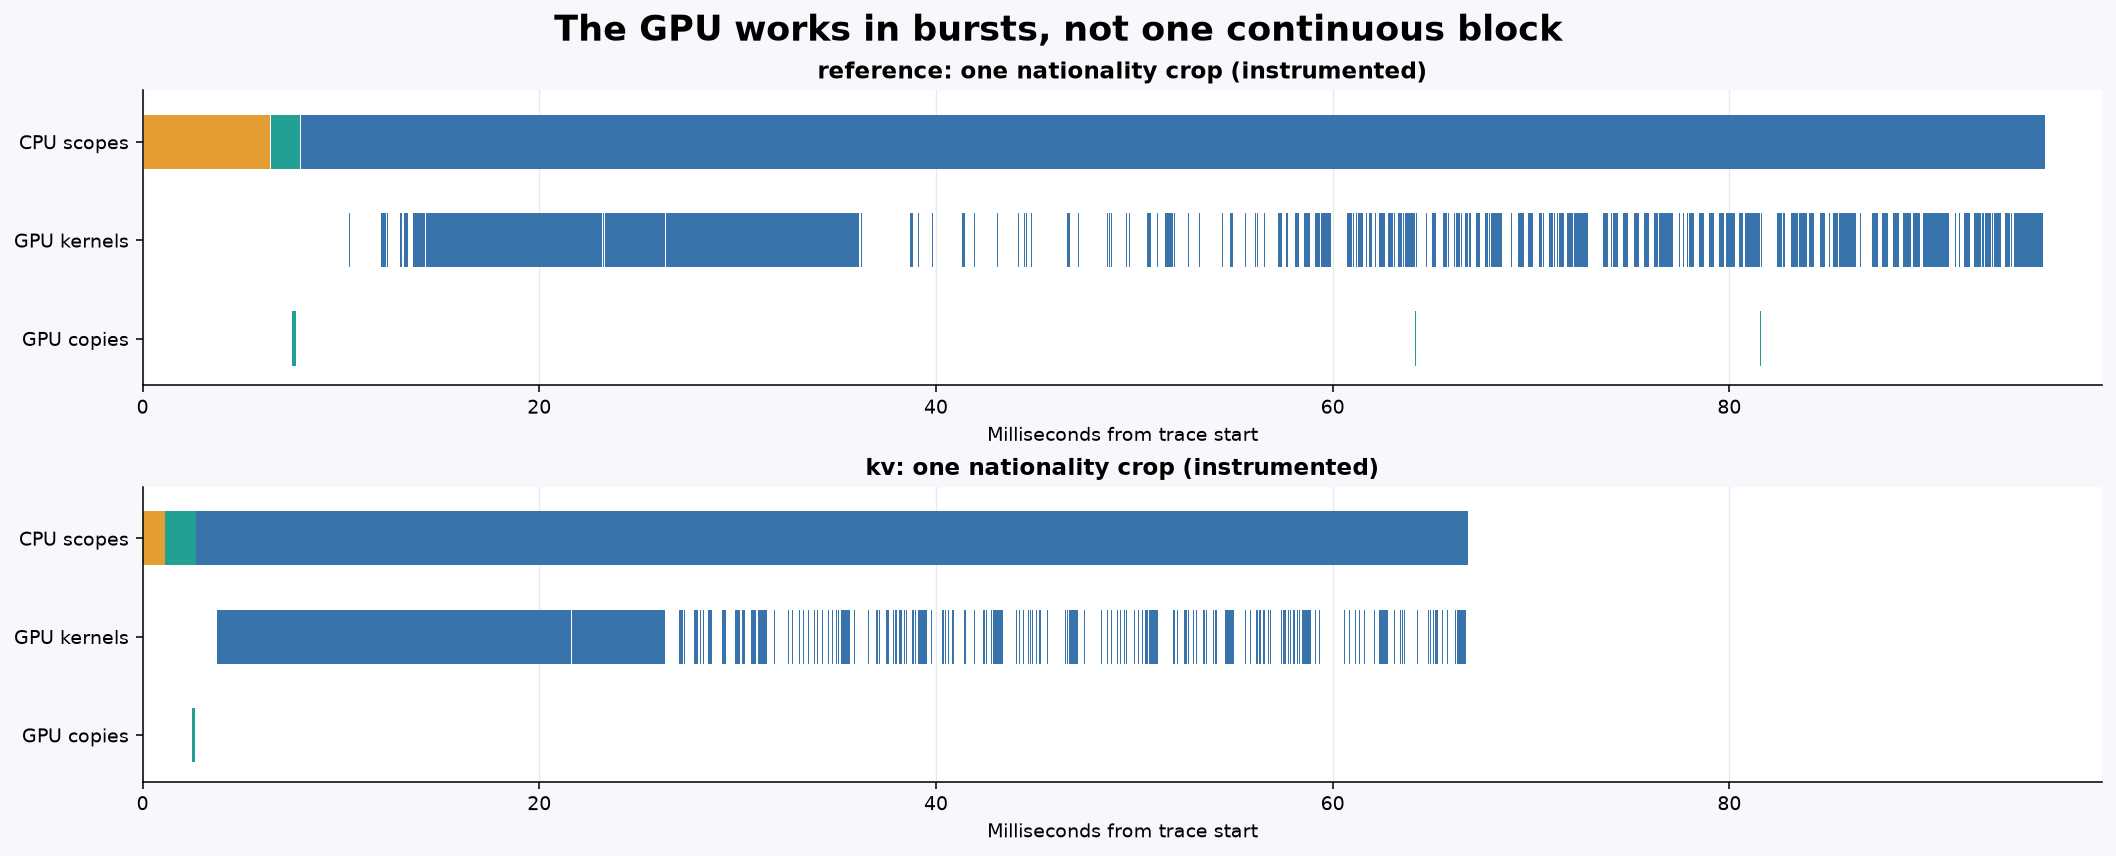

In [6]:
trace_table = trace_figure(run_directory, figure_directory / "trace.png")
display(trace_table.round(3))
display(Image(filename=str(figure_directory / "trace.png")))

## What the recorded run taught us

- A one-CPU quota with four threads made sequential OCR take 805 ms. Matching
  thread pools to that budget restored 297 ms, without changing a prediction.
- Batching seven fields took about 198 ms and increased peak live tensor VRAM
  from 256 to 328 MiB. It still could not sustain eight arrivals per second.
- H2D was about 1.7 ms per document. Pinning on the request path could cost more
  than it saved. Optimizing transfer alone was not the big opportunity.
- Decoder KV cache was a modest local improvement. A 1.26 ms result hit is
  different: it avoided recognition entirely and required an identical request.
- A 290 ms service can produce a 1.45 s p95 response when a queue fills. Rejecting
  excess work is part of the observed outcome, not an omitted failure.

These statements describe the recorded run above. Reruns need fresh
interpretation; short ordered runs are not SLA estimates. No HTTP, uploads,
rectification, autoscaling, GPU partitioning, cold-disk experiment, or test-set
evaluation was added. Phase 3 stays open.

Learning check: explain which cache helps a new photo, why CPU milliseconds can
exceed wall milliseconds, and why memory reserved does not equal memory live.
Then explain why simply making the queue bigger cannot increase service capacity.